# 46 — The thesis graphs, by question

Every graph and table of the thesis analysis chapter, drawn one per file and saved per question and per slot:

    <output>/thesis_figures/Q1_growth/results/   … /appendix/      (pdf, png, csv, json per item; numbers.json per question)

The seven questions are the author's index (`viz/thesis.QUESTIONS`); what each graph is and where it comes from in the
45-page document is in `viz/thesis_qN.py` (ITEMS). Numbers the document quotes are computed in `numbers(ctx)` of the same
module, never typed. Notebooks 40–44 remain the computation and the check against the document; this notebook only
draws what the thesis prints. Regenerate it with `python3 notebooks/_build/build_46.py`.

## 0. Setup

Paths from `labelling_analysis.yaml`; the analysis frame (627 unique aircraft) built once.

In [1]:
import sys, pathlib, importlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from viz import config, thesis, thesis_run
cfg = config.load()
ctx = thesis.context(cfg)
OUT = cfg.out('thesis_figures')
print(len(ctx.v), 'unique aircraft;', 'output:', OUT)

def item(mod, name):
    it = next(i for i in mod.ITEMS if i['name'] == name)
    obj, data = it['builder'](ctx)
    path = thesis.save_item(it, obj, data, cfg)
    print(it['slot'], '|', it['source_item'], '|', ('FLAG ' + it['flag'] + ': ' + it['flag_note']) if it['flag'] else '', '->', path.name)
    if it['kind'] == 'figure':
        plt.show()
    else:
        display(obj)
    return path

627 unique aircraft; output: /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures


## Common numbers

The dataset, the unit of analysis, the windows and the publication lag, as the Methodology quotes them; then the chapter-level flowcharts of the Methodology (`thesis_common.METHOD_ITEMS`), saved to `common/`.

method | How the chapter is organised -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/common/common_chapter_flow.pdf


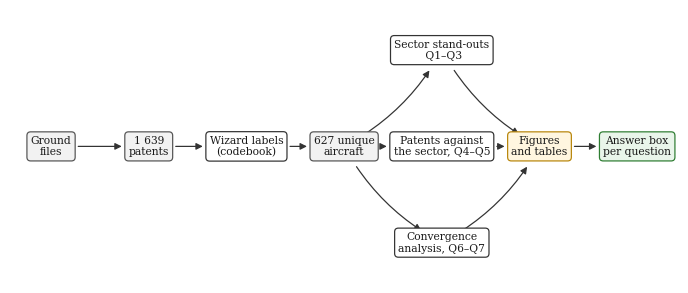

method | How the dataset is built -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/common/common_data_flow.pdf


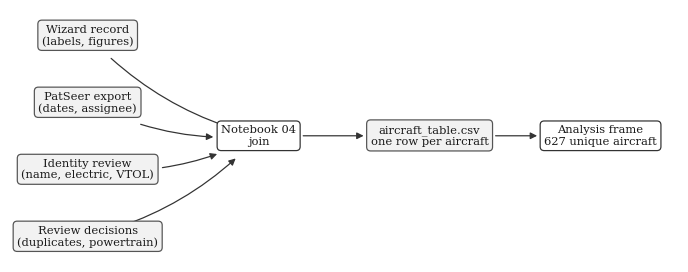

,value
acquired_s,1 639
representative_s,879
observations_s,963
unique_s,627
snapshot,2026-06-08
partial_start,2024
last_complete,2023
lag_median_lo,1
lag_median_hi,2
lag_p90,3


In [2]:
from viz import thesis_common
import json
nums = thesis_common.numbers(ctx)
p = OUT / 'common' / 'numbers.json'; p.parent.mkdir(exist_ok=True)
p.write_text(json.dumps(nums, indent=1, ensure_ascii=False), encoding='utf-8')
for it in thesis_common.METHOD_ITEMS:                       # common_chapter_flow, common_data_flow
    fig, _ = it['builder'](ctx)
    print(it['slot'], '|', it['title'], '->', thesis_common.save_common(it, fig, cfg))
    plt.show()
pd.Series(nums, name='value').to_frame()

## Q1. How fast does it grow, and where?

*eVTOL sector stand-outs.* Module `viz/thesis_q1.py`; text `viz/thesis_text_q1.py`.

In [3]:
from viz import thesis_q1 as m1
importlib.reload(m1)
print(len(m1.ITEMS), 'items')

6 items


### Q1 — Method

#### How Q1 is answered

How Q1 is answered. *(from new)*

method | new |  -> q1_method_flow.pdf


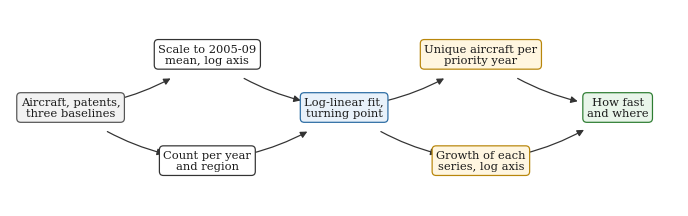

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/method/q1_method_flow.pdf')

In [4]:
item(m1, 'q1_method_flow')

### Q1 — Results

#### A. Unique aircraft per priority year

Unique aircraft by the priority year of their first patent, stacked by applicant region, with the representative patents as a line and the dated sector events under the bars. *(from Figure 1 (i))*

results | Figure 1 (i) |  -> q1_filings_per_year.pdf


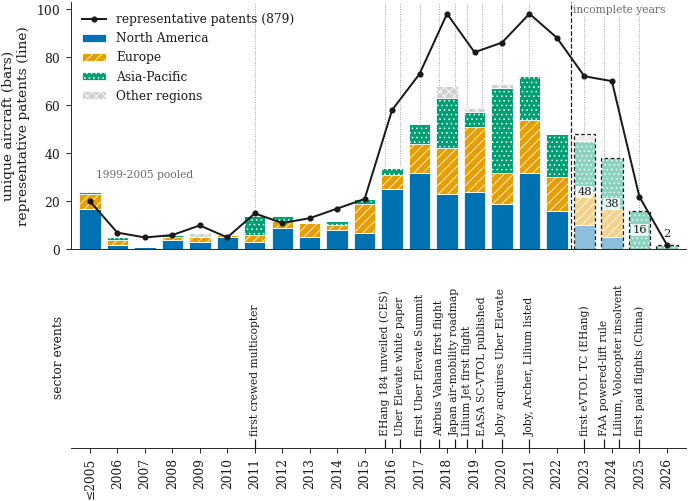

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/results/q1_filings_per_year.pdf')

In [5]:
item(m1, 'q1_filings_per_year')

#### A. Growth of each series, log axis

eVTOL architecture patents against three worldwide baselines (WIPO, PatSeer), each relative to its own 2005-09 mean on a log axis, with its fitted line over 2005-2023. *(from Figure 1 (ii))*

results | Figure 1 (ii) |  -> q1_growth_rates.pdf


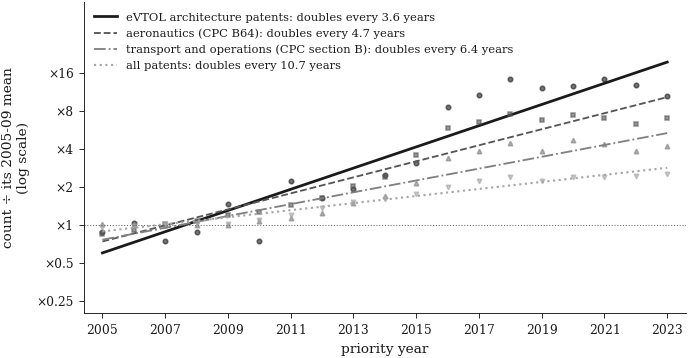

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/results/q1_growth_rates.pdf')

In [6]:
item(m1, 'q1_growth_rates')

### Q1 — Appendix

#### A. Doubling times against the baselines

Doubling time of every series over 2005-2023 with its bootstrap interval, and how many times as fast the eVTOL architecture patents grow against each baseline. *(from la_growth_rates / la_growth_ratios (Figure 1 ii data))*

In [7]:
item(m1, 'q1_growth_rates_table')

appendix | la_growth_rates / la_growth_ratios (Figure 1 ii data) |  -> q1_growth_rates_table.csv


,series,families 2005-2023,doubling time (years),95 % interval,growth per year,eVTOL patents grow ... times as fast
0,eVTOL architecture patents,771,3.6,3.0 to 4.4,21 %,
1,eVTOL unique aircraft,554,3.7,2.9 to 5.0,21 %,
2,aeronautics (CPC B64),150730,4.7,4.1 to 5.6,16 %,1.32 (1.20 to 1.46)
3,transport and operations (CPC section B),5265857,6.4,5.4 to 7.9,11 %,1.79 (1.61 to 1.94)
4,all patents,28415596,10.7,9.6 to 12.2,7 %,3.00 (2.71 to 3.35)


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/appendix/q1_growth_rates_table.csv')

#### B. Aircraft per priority year and region

Unique aircraft per priority year and applicant region from 2012, North America's share printed on its segment, the years the snapshot has not fully seen faded. *(from Figure 23 (i))*

appendix | Figure 23 (i) |  -> q1_na_drop_is_real.pdf


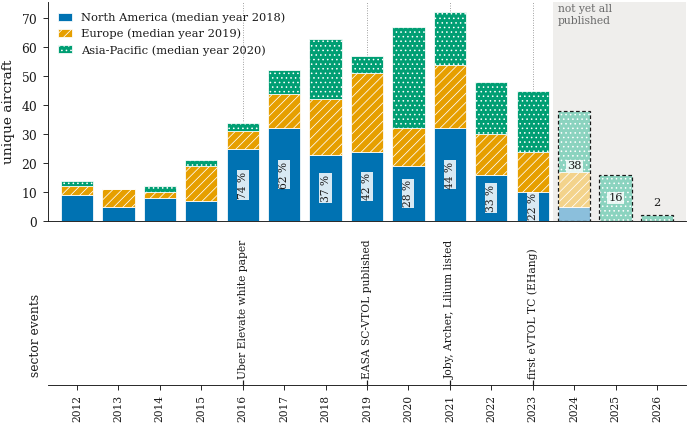

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/appendix/q1_na_drop_is_real.pdf')

In [8]:
item(m1, 'q1_na_drop_is_real')

#### B. Aircraft with no patent in force, per class

Share of each class's aircraft with no patent left in force at the snapshot, priority year 2019 or earlier, classes of ten aircraft or more. *(from Figure 4)*

appendix | Figure 4 |  -> q1_in_force_status.pdf


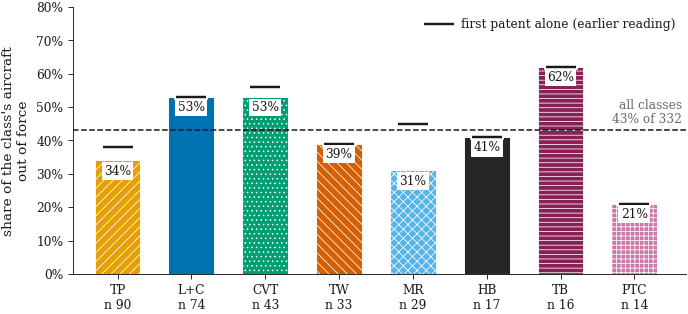

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/appendix/q1_in_force_status.pdf')

In [9]:
item(m1, 'q1_in_force_status')

### Q1 — numbers and text checks

Every number the Q1 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [10]:
nums = thesis_run.write_numbers('Q1', ctx)
problems = thesis_run.check_text('Q1', nums, [i['name'] for i in m1.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 66 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q1_growth/numbers.json
text checks: clean


,value
unique_s,627
representative_s,879
lag_p90,3
boot_draws,2 000
turn_draws,2 000
...,...
fo_else,69 %
fo_wo,94 %
fo_cn,91 %
fo_p_us,0.43


## Q2. Who fills the field, and does anyone control it?

*eVTOL sector stand-outs.* Module `viz/thesis_q2.py`; text `viz/thesis_text_q2.py`.

In [11]:
from viz import thesis_q2 as m2
importlib.reload(m2)
print(len(m2.ITEMS), 'items')

7 items


### Q2 — Method

#### How Q2 is answered

How Q2 is answered. *(from new)*

method | new |  -> q2_method_flow.pdf


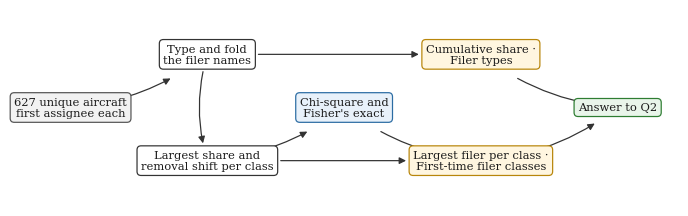

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/method/q2_method_flow.pdf')

In [12]:
item(m2, 'q2_method_flow')

### Q2 — Results

#### A. Cumulative share held by the largest filers

The named organisations ranked by unique aircraft, largest first, and the cumulative share of the aircraft they hold, cut into four bands; hollow diamonds are the firms the AAM Reality Index rates. *(from Figure 16 (i))*

results | Figure 16 (i) |  -> q2_largest_filers_share.pdf


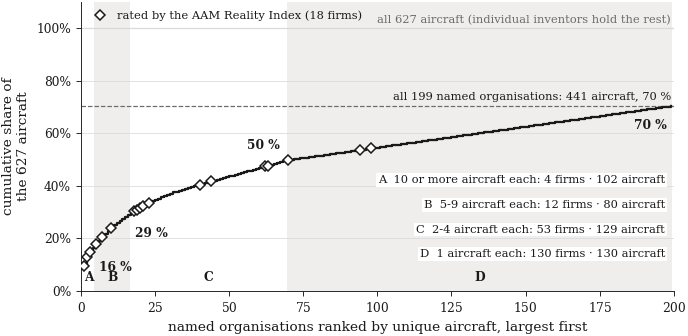

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/results/q2_largest_filers_share.pdf')

In [13]:
item(m2, 'q2_largest_filers_share')

#### A. Filer types, all years and per window

The share of each filer type over all years, in representative patents and in aircraft, then per priority window in aircraft; the window 2024-26 is still filling (faded). *(from Figure 16 (ii))*

results | Figure 16 (ii) |  -> q2_filer_types.pdf


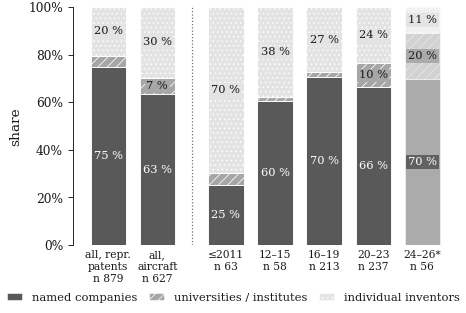

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/results/q2_filer_types.pdf')

In [14]:
item(m2, 'q2_filer_types')

#### B. Largest filer of each class

The classes of 20 aircraft or more: filers, effective number of filers (1 / Σ sᵢ²), the largest filer over all years and the highest share one filer holds inside a single priority window of 10 or more of the class's aircraft. *(from Figure 17 (i))* — **decide**: Author decides: the table may be redundant with the text of B; keep one of the two in the main text.

In [15]:
item(m2, 'q2_largest_filer_per_class')

results | Figure 17 (i) | FLAG decide: Author decides: the table may be redundant with the text of B; keep one of the two in the main text. -> q2_largest_filer_per_class.csv


,class,aircraft,filers,effective filers,"largest filer, all years",its share,highest share in one window
0,Lift + Cruise,165,105,57,Airbus,7 %,"29 % (one inventor, before 2012)"
1,Tilt Propulsor,151,100,25,Bell / Textron,18 %,"34 % (Bell / Textron, in 2016-19)"
2,Combined Vectored Thrust,106,67,24,Bell / Textron,16 %,"21 % (Bell / Textron, in 2016-19)"
3,Tilt Wing,56,43,25,Bell / Textron,14 %,"21 % (Bell / Textron, in 2020-23)"
4,Multirotor,48,36,26,Airbus,8 %,"25 % (Airbus, in 2016-19)"
5,Pitch-to-Cruise,25,21,18,Airbus,12 %,"25 % (Airbus, in 2016-19)"
6,Tilt Body,24,20,13,Bell / Textron,21 %,"33 % (Bell / Textron, in 2016-19)"


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/results/q2_largest_filer_per_class.csv')

### Q2 — Appendix

#### B. First-time and returning organisations per window

The named organisations filing in each priority window: filing for the first time (number inside the dark bar) and filing again (above the bar); the window 2024-26 is still filling (faded). *(from Figure 16 (iii))*

appendix | Figure 16 (iii) |  -> q2_first_vs_returning_filers.pdf


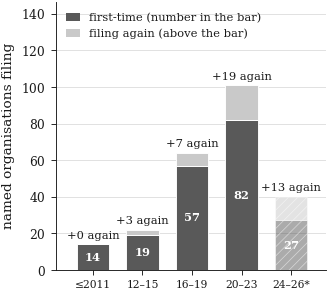

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/appendix/q2_first_vs_returning_filers.pdf')

In [16]:
item(m2, 'q2_first_vs_returning_filers')

#### B. Classes of first-time and returning filers

The classes of the aircraft of first-time and returning named organisations in the two windows that can be tested, with the chi-square p and the returning firm that holds most of the returning aircraft. *(from Figure 19 (i))*

appendix | Figure 19 (i) |  -> q2_entrant_class_mix.pdf


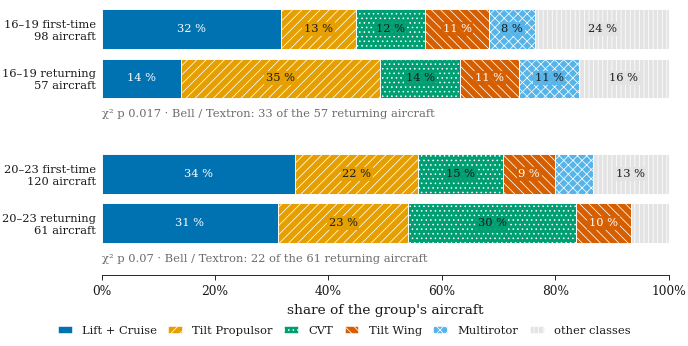

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/appendix/q2_entrant_class_mix.pdf')

In [17]:
item(m2, 'q2_entrant_class_mix')

#### B. Tilt Wing among the entering firms

Tilt Wing's share of the firms entering in each window (hatched) beside its share of all the window's aircraft (grey); the fraction under each window counts the Tilt Wing aircraft over all aircraft. *(from Figure 19 (ii))*

appendix | Figure 19 (ii) |  -> q2_tilt_wing_entrants.pdf


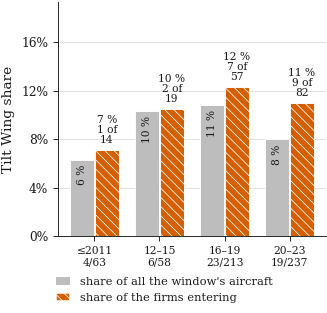

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/appendix/q2_tilt_wing_entrants.pdf')

In [18]:
item(m2, 'q2_tilt_wing_entrants')

### Q2 — numbers and text checks

Every number the Q2 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [19]:
nums = thesis_run.write_numbers('Q2', ctx)
problems = thesis_run.check_text('Q2', nums, [i['name'] for i in m2.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 98 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q2_filers/numbers.json
text checks: clean


,value
n_aircraft,627
n_rep,879
w1619,2016-19
w2023,2020-23
w1215,2012-15
...,...
tw_single_2023,6
ent_uni_share_2023,18 %
ent_single_share_2023,68 %
tw_uni_share_2023,33 %


## Q3. Do the regions, and the firms within them, take different routes?

*eVTOL sector stand-outs.* Module `viz/thesis_q3.py`; text `viz/thesis_text_q3.py`.

In [20]:
from viz import thesis_q3 as m3
importlib.reload(m3)
print(len(m3.ITEMS), 'items')

8 items


### Q3 — Method

#### How Q3 is answered

How Q3 is answered. *(from new)*

method | new |  -> q3_method_flow.pdf


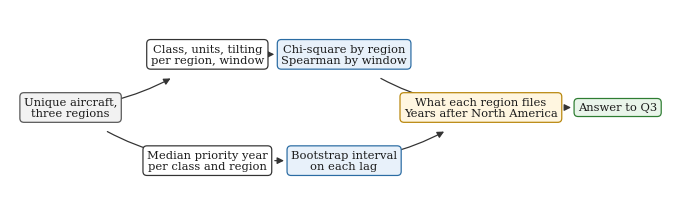

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/method/q3_method_flow.pdf')

In [21]:
item(m3, 'q3_method_flow')

### Q3 — Results

#### A. What each region files, all years

The class, the propulsor-unit band and the tilting share of each region's aircraft, all years together; each bar is 100 % of the region's aircraft with the field recorded. *(from Figure 22 (all years bars))*

results | Figure 22 (all years bars) |  -> q3_region_design_all_years.pdf


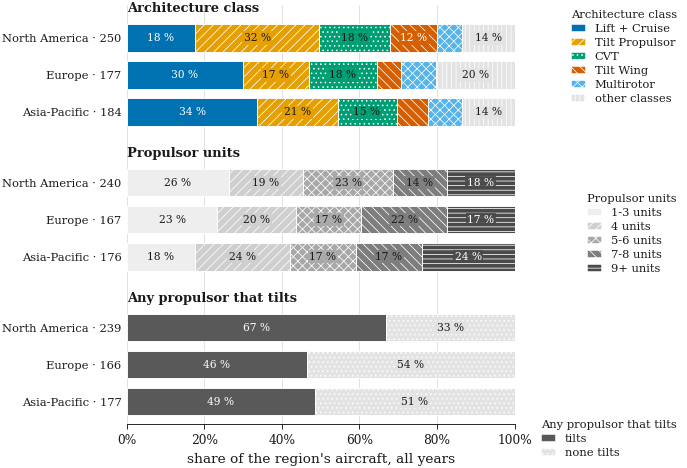

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/results/q3_region_design_all_years.pdf')

In [22]:
item(m3, 'q3_region_design_all_years')

#### B. Years after North America, per class

The years by which Europe and Asia-Pacific file each class after North America, as the median priority-year difference with its 95 % bootstrap interval. *(from Figure 23 (ii))* — **verify**: verify: an interval touching 0 is read here as not detected (the 2016-onward Tilt Propulsor delay, 0 to +4); the 45-page document calls that same interval detected

results | Figure 23 (ii) | FLAG verify: verify: an interval touching 0 is read here as not detected (the 2016-onward Tilt Propulsor delay, 0 to +4); the 45-page document calls that same interval detected -> q3_region_entry_lag.pdf


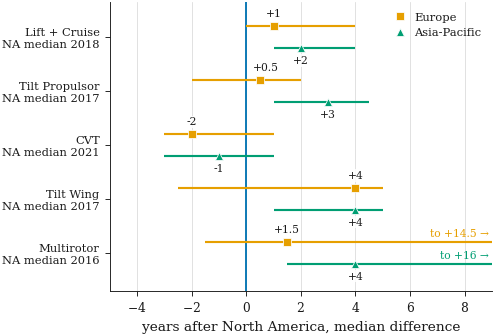

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/results/q3_region_entry_lag.pdf')

In [23]:
item(m3, 'q3_region_entry_lag')

### Q3 — Appendix

#### A. Class per region and window

The class mix of each region's aircraft per priority window, with the two strongest trends over 2012-2023 above each panel. *(from Figure 22 (i), per-window bars)* — **decide**: the index wrote 'Figure 21' here; the per-window panels of Figure 22 are these three (one variable each): decide whether they stay in the appendix

appendix | Figure 22 (i), per-window bars | FLAG decide: the index wrote 'Figure 21' here; the per-window panels of Figure 22 are these three (one variable each): decide whether they stay in the appendix -> q3_region_mix_by_window_class.pdf


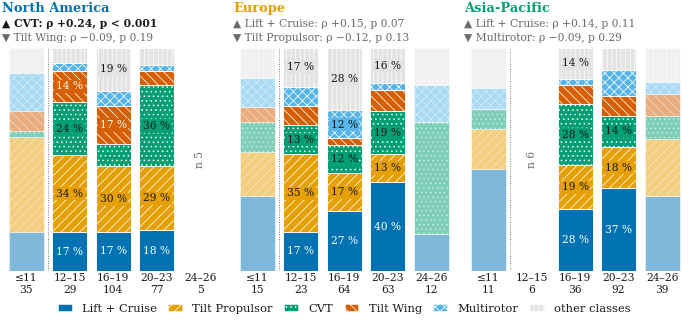

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/appendix/q3_region_mix_by_window_class.pdf')

In [24]:
item(m3, 'q3_region_mix_by_window_class')

#### A. Propulsor units per region and window

The propulsor-unit band of each region's aircraft per priority window, with the two strongest trends over 2012-2023 above each panel. *(from Figure 22 (ii), per-window bars)* — **decide**: the index wrote 'Figure 21' here; the per-window panels of Figure 22 are these three (one variable each): decide whether they stay in the appendix

appendix | Figure 22 (ii), per-window bars | FLAG decide: the index wrote 'Figure 21' here; the per-window panels of Figure 22 are these three (one variable each): decide whether they stay in the appendix -> q3_region_mix_by_window_units.pdf


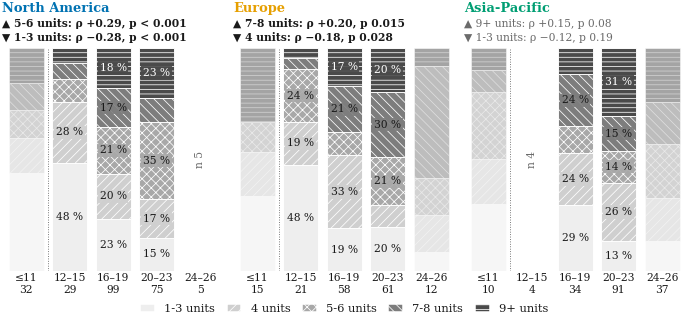

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/appendix/q3_region_mix_by_window_units.pdf')

In [25]:
item(m3, 'q3_region_mix_by_window_units')

#### A. Tilting share per region and window

The share of each region's aircraft with a tilting propulsor per priority window, with the trend over 2012-2023 above each panel. *(from Figure 22 (iii), per-window bars)* — **decide**: the index wrote 'Figure 21' here; the per-window panels of Figure 22 are these three (one variable each): decide whether they stay in the appendix

appendix | Figure 22 (iii), per-window bars | FLAG decide: the index wrote 'Figure 21' here; the per-window panels of Figure 22 are these three (one variable each): decide whether they stay in the appendix -> q3_region_mix_by_window_tilting.pdf


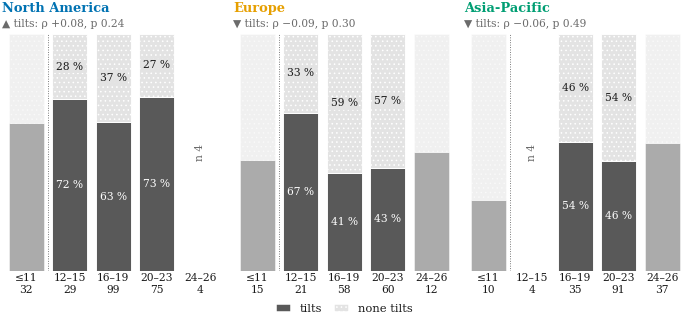

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/appendix/q3_region_mix_by_window_tilting.pdf')

In [26]:
item(m3, 'q3_region_mix_by_window_tilting')

#### A. The applicant countries behind the regions

Patents acquired (pale) and representative patents (dark) per applicant country, the ten largest, with each country's unique aircraft. *(from Figure 21)* — **decide**: appendix or drop: the base of the regions, not an answer to the question

appendix | Figure 21 | FLAG decide: appendix or drop: the base of the regions, not an answer to the question -> q3_region_countries.pdf


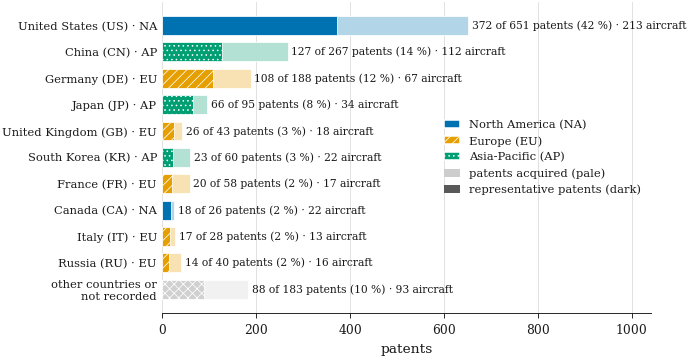

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/appendix/q3_region_countries.pdf')

In [27]:
item(m3, 'q3_region_countries')

#### B. Where a firm's next aircraft lands

Where a named firm's next aircraft lands, by the class of the one before; each row sums to 100 % and the boxed cell is the share that stays in the class. *(from Figure 20)*

appendix | Figure 20 |  -> q3_firm_successions.pdf


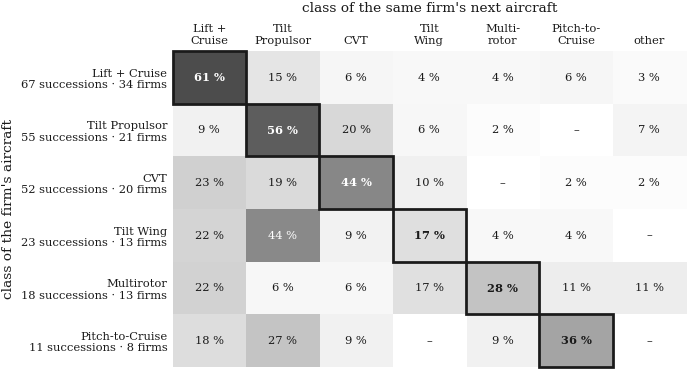

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/appendix/q3_firm_successions.pdf')

In [28]:
item(m3, 'q3_firm_successions')

### Q3 — numbers and text checks

Every number the Q3 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [29]:
nums = thesis_run.write_numbers('Q3', ctx)
problems = thesis_run.check_text('Q3', nums, [i['name'] for i in m3.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 131 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q3_regions/numbers.json
text checks: clean


,value
all_n,627
three_n,613
three_share,98 %
other_n,14
na_n,250
...,...
tw_firms,13
tw_to_tr,44 %
tw_to_slc,22 %
big_firm,Bell / Textron


## Q4. Do the patented aircraft stand for the aircraft that get built?

*Patents against the built and funded sector.* Module `viz/thesis_q4.py`; text `viz/thesis_text_q4.py`.

In [30]:
from viz import thesis_q4 as m4
importlib.reload(m4)
print(len(m4.ITEMS), 'items')

11 items


### Q4 — Method

#### How Q4 is answered

How Q4 is answered. *(from new)*

method | new |  -> q4_method_flow.pdf


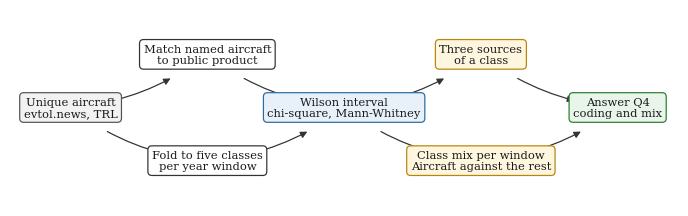

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/method/q4_method_flow.pdf')

In [31]:
item(m4, 'q4_method_flow')

### Q4 — Results

#### A. Three sources of a class, two at a time

Agreement on the architecture class between the drawing label, the patent text and the public aircraft, on the aircraft with a public counterpart; 95 % Wilson interval with the finite-population correction. *(from Table 2)*

In [32]:
item(m4, 'q4_coding_agreement')

results | Table 2 |  -> q4_coding_agreement.csv


,comparison,agree,of,share,95 % interval,the disagreements
0,drawing label against the public aircraft,87,97,0.90,0.83–0.94,the patent describes another configuration tha...
1,patent text against the public aircraft,89,97,0.92,0.85–0.96,the patent describes another configuration tha...
2,drawing label against the patent text,93,97,0.96,0.91–0.98,the drawing was read as one class and the text...


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/results/q4_coding_agreement.csv')

#### B. Class mix per window, labelled dataset

The class mix of the labelled dataset per priority-year window, folded to the five classes of the evtol.news directory; the aircraft of each window under its bar. *(from Figure 2 (i))*

results | Figure 2 (i) |  -> q4_class_mix_dataset.pdf


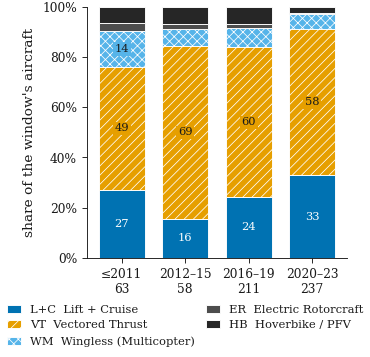

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/results/q4_class_mix_dataset.pdf')

In [33]:
item(m4, 'q4_class_mix_dataset')

#### B. Class mix per window, evtol.news directory

The evtol.news directory's own class mix per development-year window, on the same axis and class order as the labelled dataset; the aircraft of each window under its bar. *(from Figure 2 (ii))*

results | Figure 2 (ii) |  -> q4_class_mix_directory.pdf


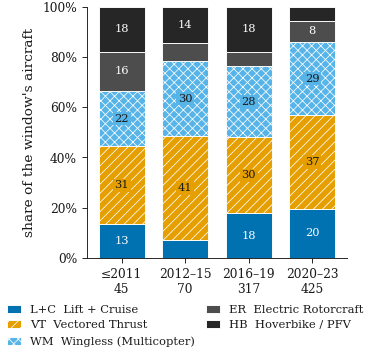

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/results/q4_class_mix_directory.pdf')

In [34]:
item(m4, 'q4_class_mix_directory')

#### B. The patent clock against the market clock

The AAM Reality Index firms that file in this corpus, one row each: first to last priority year, the peak filing year, and the first flight and entry into service the index states. *(from Figure 3)* — **decide**: main text or appendix

results | Figure 3 | FLAG decide: main text or appendix -> q4_patent_vs_market_clock.pdf


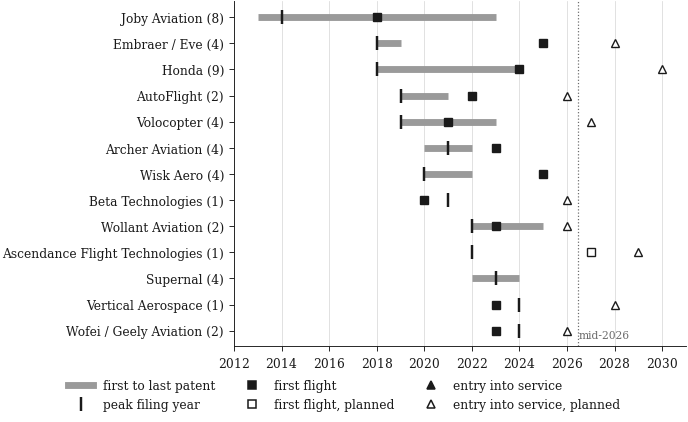

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/results/q4_patent_vs_market_clock.pdf')

In [35]:
item(m4, 'q4_patent_vs_market_clock')

#### B. Aircraft above TRL 2 against the rest

The aircraft above NASA TRL 2 against the rest of the labelled dataset on six attributes, one test per attribute: chi-square for a category, Mann-Whitney for a number. *(from Table 4)* — **verify**: author re-verifies these values and the evtol.news class mapping; the folded-class row differs from the 45-page document by the SRW→LC ruling of 2026-10-01

In [36]:
item(m4, 'q4_trl_representativeness')

results | Table 4 | FLAG verify: author re-verifies these values and the evtol.news class mapping; the folded-class row differs from the 45-page document by the SRW→LC ruling of 2026-10-01 -> q4_trl_representativeness.csv


,attribute,n above TRL 2,n rest,largest gap,test,p,verdict
0,folded class,63,564,LC (+6.4 pp),chi-square,0.11,no difference detected
1,applicant region,63,564,Asia-Pacific (-4.7 pp),chi-square,0.83,no difference detected
2,priority window,63,564,2020-23 (+12.7 pp),chi-square,0.07,no difference detected
3,filer type,63,564,Named company (+35.5 pp),chi-square,< 0.001,differs
4,priority year,63,564,median +1.0,Mann-Whitney,0.05,no difference detected
5,propulsive units,63,564,median +3.0,Mann-Whitney,< 0.001,differs


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/results/q4_trl_representativeness.csv')

#### B. Index-firm aircraft against the rest

The aircraft of the AAM Reality Index firms against the rest of the labelled dataset on six attributes, one test per attribute. *(from Table 5)* — **verify**: author re-verifies these values and the evtol.news class mapping; the folded-class row differs from the 45-page document by the SRW→LC ruling of 2026-10-01

In [37]:
item(m4, 'q4_index_firm_representativeness')

results | Table 5 | FLAG verify: author re-verifies these values and the evtol.news class mapping; the folded-class row differs from the 45-page document by the SRW→LC ruling of 2026-10-01 -> q4_index_firm_representativeness.csv


,attribute,n index firms,n rest,largest gap,test,p,verdict
0,folded class,147,480,VT (+7.3 pp),chi-square,0.15,no difference detected
1,applicant region,147,480,North America (+28.8 pp),chi-square,< 0.001,differs
2,priority window,147,480,2016-19 (+18.7 pp),chi-square,< 0.001,differs
3,filer type,147,480,Named company (+47.9 pp),chi-square,< 0.001,differs
4,priority year,147,480,median +0.0,Mann-Whitney,0.41,no difference detected
5,propulsive units,147,480,median +1.0,Mann-Whitney,< 0.001,differs


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/results/q4_index_firm_representativeness.csv')

### Q4 — Appendix

#### B. Dataset against directory, all years

Unique aircraft per directory class in the labelled dataset (filled) and in the evtol.news directory (outline), all years together, with the share of each source and its 95 % Wilson interval. *(from Figure 5b (i))*

appendix | Figure 5b (i) |  -> q4_dataset_vs_directory_classes.pdf


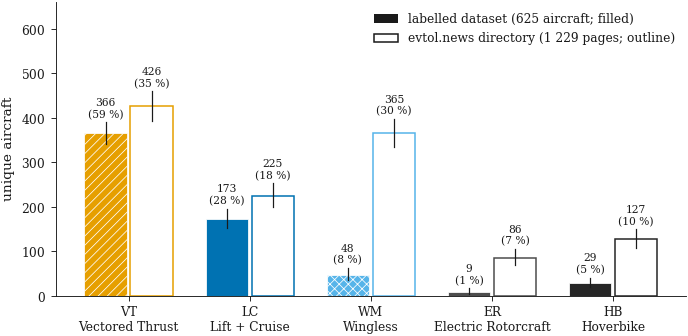

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/appendix/q4_dataset_vs_directory_classes.pdf')

In [38]:
item(m4, 'q4_dataset_vs_directory_classes')

#### B. Aircraft of each class per part of the directory

For each directory class, the aircraft in the labelled dataset and in five parts of the directory that could explain a different mix: in domain, concept designs, flying hardware, linked to a patent or not. *(from Figure 5b (ii))*

appendix | Figure 5b (ii) |  -> q4_dataset_vs_directory_subsets.pdf


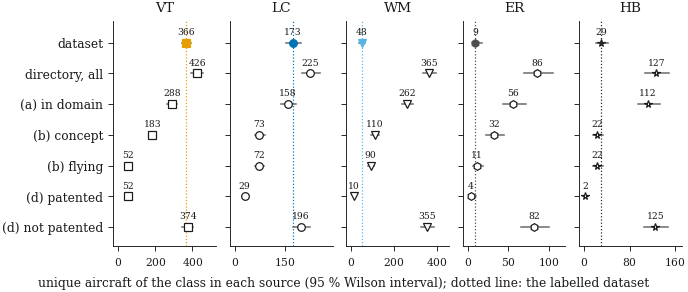

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/appendix/q4_dataset_vs_directory_subsets.pdf')

In [39]:
item(m4, 'q4_dataset_vs_directory_subsets')

#### B. NASA TRL per class

Technology readiness (NASA TRL) reached by the unique aircraft, per architecture class; an aircraft no public source follows is TRL 2 by construction. *(from Table 3)* — **drop**: kept in the appendix; proposed to be dropped

In [40]:
item(m4, 'q4_trl_by_class')

appendix | Table 3 | FLAG drop: kept in the appendix; proposed to be dropped -> q4_trl_by_class.csv


,class,unique aircraft,TRL 2,TRL 3-5,TRL 6-7,TRL 8-9,above TRL 2,share above TRL 2
0,Lift + Cruise,165,144,4,16,1,21,0.13
1,Tilt Propulsor,151,133,5,13,0,18,0.12
2,Combined Vectored Thrust,106,99,0,7,0,7,0.07
3,Tilt Wing,56,51,3,2,0,5,0.09
4,Multirotor,48,40,0,8,0,8,0.17
5,Pitch-to-Cruise,25,24,0,1,0,1,0.04
6,Tilt Body,24,22,2,0,0,2,0.08
7,Hoverbike,19,19,0,0,0,0,0.00
8,Personal Flying Vehicle,10,10,0,0,0,0,0.00
9,Rotorcraft,9,9,0,0,0,0,0.00


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/appendix/q4_trl_by_class.csv')

#### B. Unique aircraft by name and public match

Unique aircraft that carry a real product name or an identifier generated for this study, and within each the aircraft matched to a public product. *(from Figure 5)* — **drop**: kept in the appendix; proposed to be dropped

appendix | Figure 5 | FLAG drop: kept in the appendix; proposed to be dropped -> q4_name_coverage.pdf


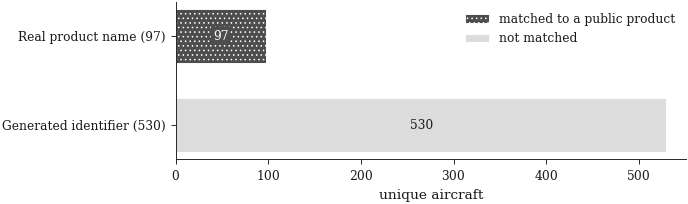

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/appendix/q4_name_coverage.pdf')

In [41]:
item(m4, 'q4_name_coverage')

### Q4 — numbers and text checks

Every number the Q4 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [42]:
nums = thesis_run.write_numbers('Q4', ctx)
problems = thesis_run.check_text('Q4', nums, [i['name'] for i in m4.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 67 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q4_representativeness/numbers.json
text checks: clean


,value
unique,627
nc_named,97
nc_gen,530
nc_gen_matched,0
pw_img_pub,87
...,...
ari_year_p,0.41
ari_units_p,< 0.001
ari_differs,4
ari_region_gap,North America (+28.8 pp)


## Q5. Does the money follow the patents, in time and in design?

*Patents against the built and funded sector.* Module `viz/thesis_q5.py`; text `viz/thesis_text_q5.py`.

In [43]:
from viz import thesis_q5 as m5
importlib.reload(m5)
print(len(m5.ITEMS), 'items')

5 items


### Q5 — Method

#### How Q5 is answered

How Q5 is answered. *(from new)*

method | new |  -> q5_method_flow.pdf


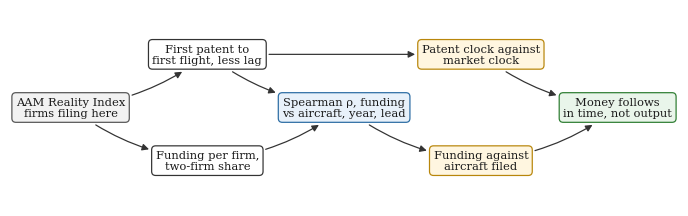

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q5_money/method/q5_method_flow.pdf')

In [44]:
item(m5, 'q5_method_flow')

### Q5 — Results

#### B. Funding against aircraft filed

Disclosed funding of the AAM Reality Index firms against their unique aircraft in the corpus, one dot per firm, with the Spearman ρ, its p and the number of firms. *(from Figure 18 (i))*

results | Figure 18 (i) |  -> q5_funding_vs_aircraft.pdf


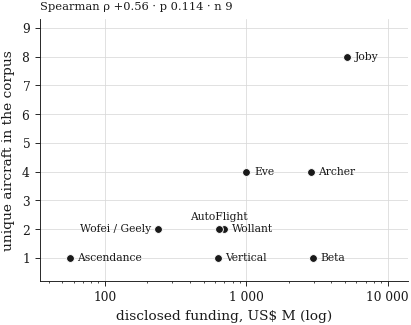

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q5_money/results/q5_funding_vs_aircraft.pdf')

In [45]:
item(m5, 'q5_funding_vs_aircraft')

### Q5 — Appendix

#### A. Patent clock against market clock

The index firms that file in this corpus: first patent here, first flight and entry into service as the AAM Reality Index states them, and the years between. A negative value means the firm flew before its first filing in this corpus. *(from Table 1)* — **decide**: appendix as proposed, or main text beside the Timing paragraph; the lead is a floor (first patent IN THIS CORPUS)

In [46]:
item(m5, 'q5_ari_timeline')

appendix | Table 1 | FLAG decide: appendix as proposed, or main text beside the Timing paragraph; the lead is a floor (first patent IN THIS CORPUS) -> q5_ari_timeline.csv


,company,first patent,aircraft,first flight,entry into service,years to first flight,years to entry into service
0,Joby Aviation,2013,8,2018,,5,
1,Embraer / Eve,2018,4,2025,2028,7,10
2,Honda,2018,9,2024,2030,6,12
3,AutoFlight,2019,2,2022,2026,3,7
4,Volocopter,2019,4,2021,2027,2,8
5,Archer Aviation,2020,4,2023,,3,
6,Wisk Aero,2020,4,2025,,5,
7,Beta Technologies,2021,1,2020,2026,-1,5
8,Wollant Aviation,2022,2,2023,2026,1,4
9,Ascendance Flight Technologies,2022,1,2027,2029,5,7


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q5_money/appendix/q5_ari_timeline.csv')

#### B. Funding against patent-to-flight lead

Disclosed funding of the AAM Reality Index firms against the years from their first patent in this corpus to their first flight, one dot per firm whose first flight has happened. *(from Figure 18 (ii))* — **verify**: check caption/image: the 45-page document showed no caption or image for this panel

appendix | Figure 18 (ii) | FLAG verify: check caption/image: the 45-page document showed no caption or image for this panel -> q5_patent_lead_to_flight.pdf


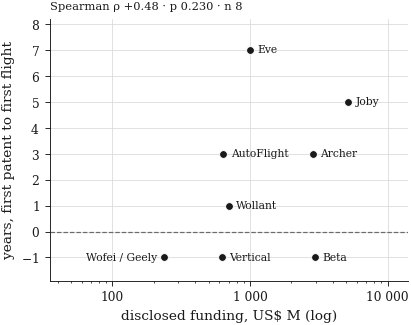

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q5_money/appendix/q5_patent_lead_to_flight.pdf')

In [47]:
item(m5, 'q5_patent_lead_to_flight')

#### C. Patenting against sector investment

Unique aircraft per priority year against the disclosed eVTOL investment per year, one dot per published funding period. An open dot is a period whose priority years are still filling. *(from new)* — **decide**: new figure from the sector_funding input; the two trackers differ in scope (VFS: eVTOL companies, cumulative 2010-2020; McKinsey: future air mobility, single years), so it is a comparison by eye, never a test

appendix | new | FLAG decide: new figure from the sector_funding input; the two trackers differ in scope (VFS: eVTOL companies, cumulative 2010-2020; McKinsey: future air mobility, single years), so it is a comparison by eye, never a test -> q5_patenting_vs_investment.pdf


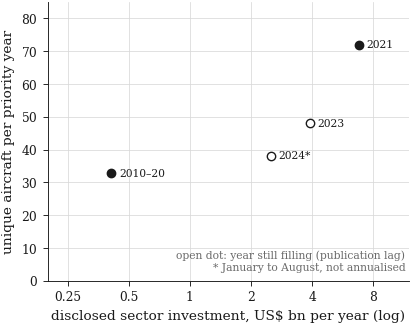

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q5_money/appendix/q5_patenting_vs_investment.pdf')

In [48]:
item(m5, 'q5_patenting_vs_investment')

### Q5 — numbers and text checks

Every number the Q5 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [49]:
nums = thesis_run.write_numbers('Q5', ctx)
problems = thesis_run.check_text('Q5', nums, [i['name'] for i in m5.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 52 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q5_money/numbers.json
text checks: clean


,value
ari_timeline_n,13
ff_record_n,11
ff_before_n,8
ff_after_n,3
ff_plan_n,1
ff_lead,4
lag_p90,3
ff_visible,1
ff_lead_min,1
ff_lead_max,7


## Q6. Where do eVTOL designs concentrate, and how have they moved?

*Convergence analysis.* Module `viz/thesis_q6.py`; text `viz/thesis_text_q6.py`.

In [50]:
from viz import thesis_q6 as m6
importlib.reload(m6)
print(len(m6.ITEMS), 'items')

20 items


### Q6 — Method

#### How Q6 is answered

How Q6 is answered, from the data to the figures and the answer. *(from new)*

method | new |  -> q6_method_flow.pdf


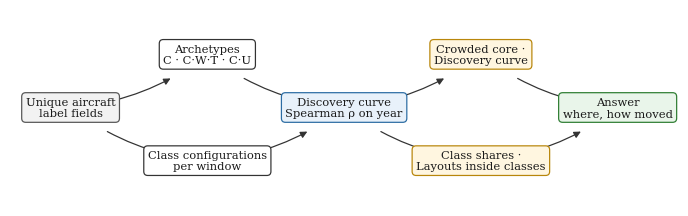

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/method/q6_method_flow.pdf')

In [51]:
item(m6, 'q6_method_flow')

### Q6 — Results

#### A. Label fields that tell designs apart

The label fields whose most common answer holds under 88 % of the aircraft: aircraft answering, different answers, top share and the most common answers. *(from Table 6)* — **decide**: Table 6 and Figure 6 (i) say the same thing from two sides; the author decides which of the two stays in the main text

In [52]:
item(m6, 'q6_selected_fields')

results | Table 6 | FLAG decide: Table 6 and Figure 6 (i) say the same thing from two sides; the author decides which of the two stays in the main text -> q6_selected_fields.csv


,field,aircraft answering,different answers,top share,most common answers: aircraft
0,number of wings,626,4,57 %,1: 359 · 2: 172 · 0: 79 · 3: 16
1,tail type,600,13,29 %,Tailless (None): 176 · Conventional (Horizonta...
2,fuselage motion hover to cruise,602,4,85 %,Fixed / Conventional: 511 · Whole-Body Pitch: ...
3,wing configuration,541,5,87 %,Standard Wings: 471 · Other: 49 · Blended Wing...
4,landing-gear type,602,3,68 %,Unknown: 411 · Wheeled Gear: 101 · Skids / Fix...
5,propulsor units per aircraft (band),596,5,23 %,0-3: 137 · 4: 125 · 5-6: 117 · 9+: 117 · 7-8: 100
6,places carrying propulsor units per aircraft,596,5,48 %,2: 286 · 1: 246 · 3: 60 · 4 or more: 3 · 0: 1


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_selected_fields.csv')

#### A. Crowded core and empty rim

C·U archetypes of five aircraft or more by their share of the 2016–23 aircraft and their distinct filers per aircraft; solid ring the crowded core, dashed the empty rim. *(from Figure 8 (i))*

results | Figure 8 (i) |  -> q6_archetype_core.pdf


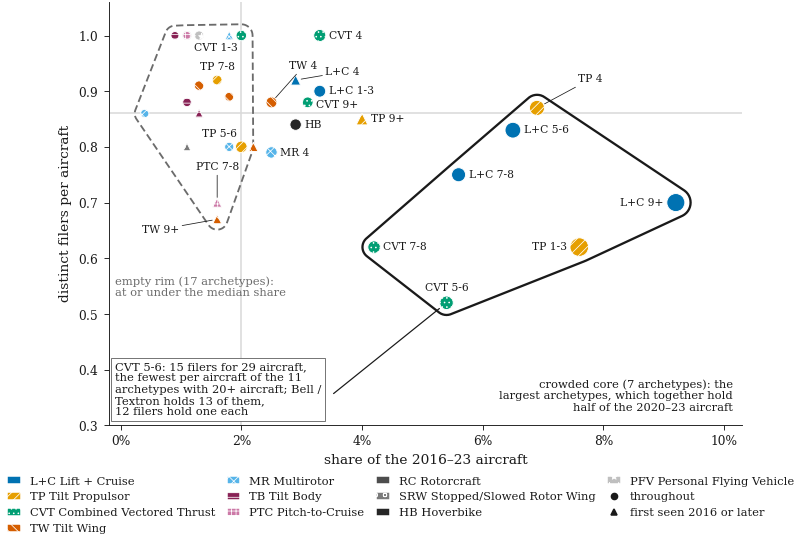

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_archetype_core.pdf')

In [53]:
item(m6, 'q6_archetype_core')

#### A. Aircraft per archetype and window

Unique aircraft of each C·U archetype per priority window, largest archetype first; the orange bar marks the column by which half the window's aircraft are reached. *(from Figure 8 (ii))*

results | Figure 8 (ii) |  -> q6_archetype_windows.pdf


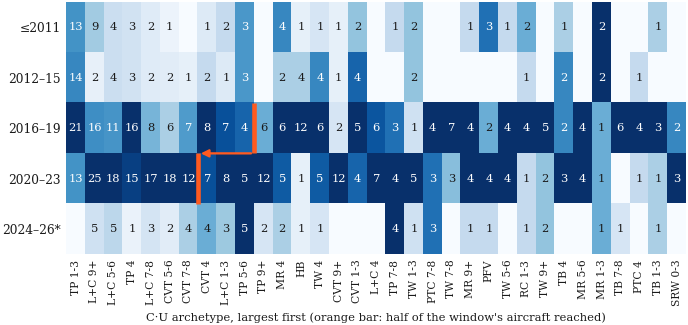

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_archetype_windows.pdf')

In [54]:
item(m6, 'q6_archetype_windows')

#### A. Is the design space still opening

Distinct archetypes seen as the aircraft accumulate in priority order, at C, C·U and C·W·T, against the same aircraft in random order. *(from Figure 9)*

results | Figure 9 |  -> q6_discovery_curve.pdf


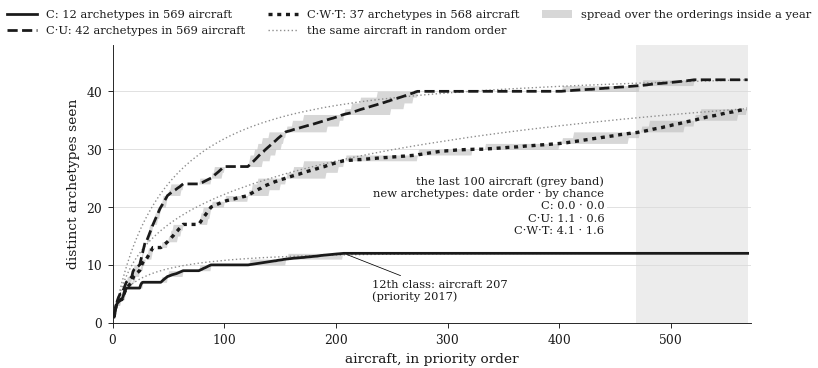

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_discovery_curve.pdf')

In [55]:
item(m6, 'q6_discovery_curve')

#### B. Class share per priority window

Share of each architecture class in the unique aircraft of each priority window; the last window is still filling. *(from Figure 10 (i))*

results | Figure 10 (i) |  -> q6_class_shares_by_window.pdf


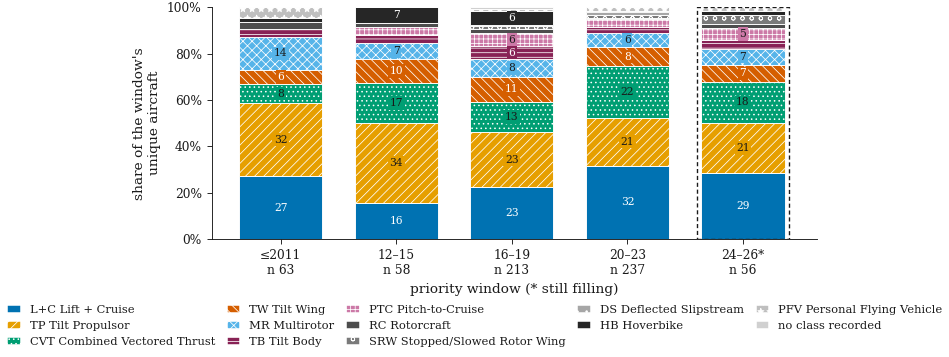

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_class_shares_by_window.pdf')

In [56]:
item(m6, 'q6_class_shares_by_window')

#### B. Five largest classes over time

The five largest classes' share of the window's unique aircraft, one line each; the last window is still filling. *(from Figure 10 (ii))*

results | Figure 10 (ii) |  -> q6_largest_classes_over_time.pdf


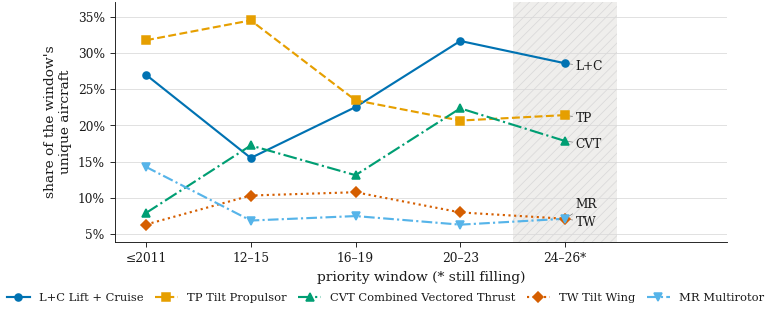

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_largest_classes_over_time.pdf')

In [57]:
item(m6, 'q6_largest_classes_over_time')

#### C. Layouts inside the three largest classes

Composition of Lift + Cruise, Tilt Propulsor and CVT over their own configurations per window, the configuration that leads in 2020–23 at the bottom. *(from Figure 13 (ii))*

results | Figure 13 (ii) |  -> q6_leading_layout_by_class.pdf


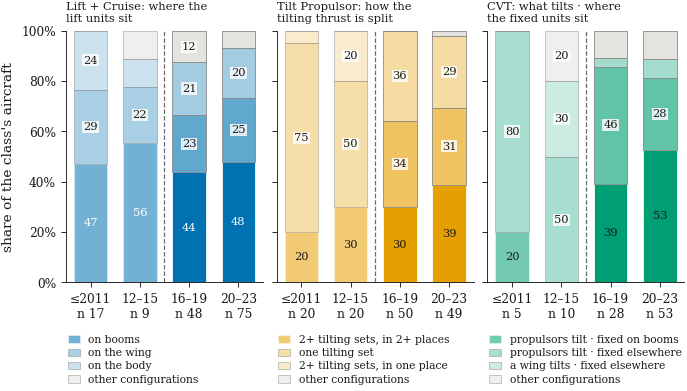

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/results/q6_leading_layout_by_class.pdf')

In [58]:
item(m6, 'q6_leading_layout_by_class')

### Q6 — Appendix

#### A. Propulsor units per class

Propulsor units of every aircraft of each class: one dot per aircraft, the bar over the middle half, the ring at the median. *(from Figure 6 (i))* — **decide**: Table 6 and Figure 6 (i) say the same thing from two sides; the author decides which of the two stays in the main text; the contract lists it beside Table 6 in the results, the limit of three result graphs per sub-question put it in the appendix

appendix | Figure 6 (i) | FLAG decide: Table 6 and Figure 6 (i) say the same thing from two sides; the author decides which of the two stays in the main text; the contract lists it beside Table 6 in the results, the limit of three result graphs per sub-question put it in the appendix -> q6_propulsor_units_per_class.pdf


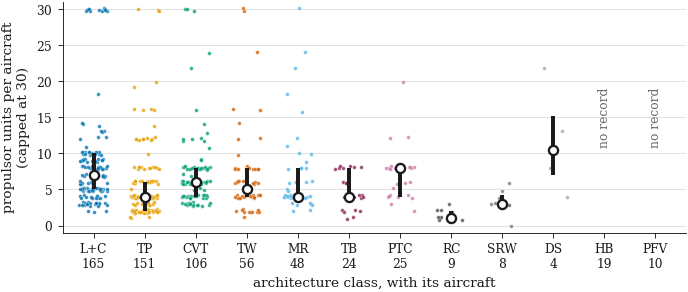

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_propulsor_units_per_class.pdf')

In [59]:
item(m6, 'q6_propulsor_units_per_class')

#### A. Arrangement features per class

Share of each class's aircraft with each arrangement feature; under the class its aircraft (read/total where a propulsion record is missing). *(from Figure 6 (ii))*

appendix | Figure 6 (ii) |  -> q6_arrangement_by_class.pdf


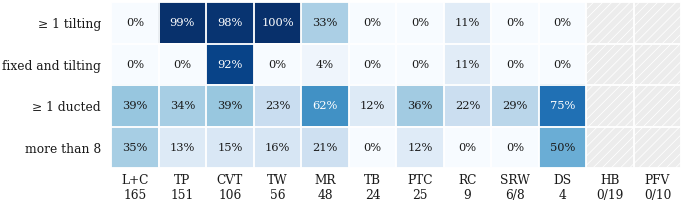

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_arrangement_by_class.pdf')

In [60]:
item(m6, 'q6_arrangement_by_class')

#### A. Ducting per propulsor-unit band

Share of each band's aircraft with a ducted propulsor, split by how much of the aircraft is ducted; the diamond is the share of the band's propulsor units in a duct. *(from Figure 6 (iii))*

appendix | Figure 6 (iii) |  -> q6_ducting_by_units.pdf


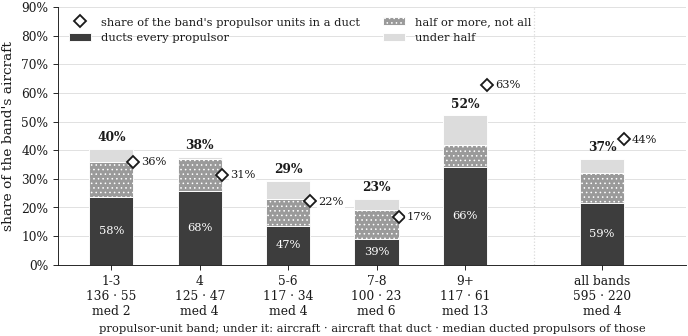

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_ducting_by_units.pdf')

In [61]:
item(m6, 'q6_ducting_by_units')

#### A. Filers per aircraft per archetype

Distinct filers per aircraft for the C·U archetypes with 20 aircraft or more; CVT with 5-6 propulsor units is outlined, CVT with 4 beside it. *(from Figure 7)* — **drop**: redundant with Figure 8 (i), whose vertical axis is the same ratio and whose callout names the one archetype that leans on one firm

appendix | Figure 7 | FLAG drop: redundant with Figure 8 (i), whose vertical axis is the same ratio and whose callout names the one archetype that leans on one firm -> q6_archetype_filers.pdf


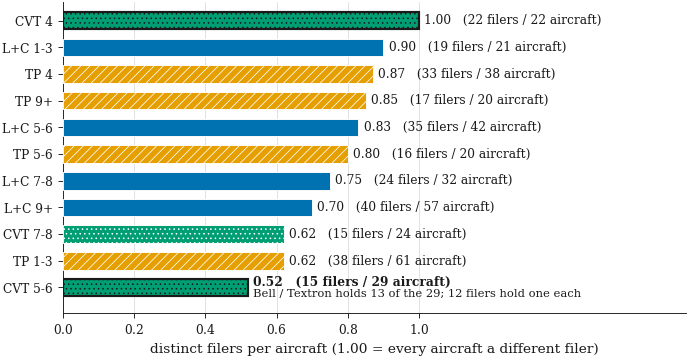

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_archetype_filers.pdf')

In [62]:
item(m6, 'q6_archetype_filers')

#### C. Share in the leading configuration

Share of each class in its most common configuration per complete window; at the right end the 2020–23 share and the configurations in use of those the rule allows. *(from Figure 13 (i))*

appendix | Figure 13 (i) |  -> q6_leading_configuration_share.pdf


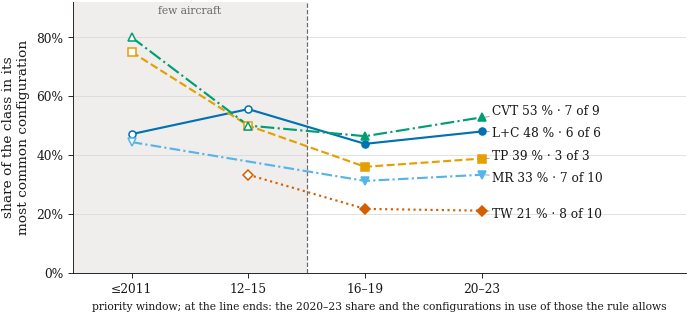

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_leading_configuration_share.pdf')

In [63]:
item(m6, 'q6_leading_configuration_share')

#### D. Class centres in tilting sets and units

Each class's centre per window, mean tilting sets against median propulsor units, joined by arrows in time order. *(from Figure 14 (i))*

appendix | Figure 14 (i) |  -> q6_class_centres_tilting_units.pdf


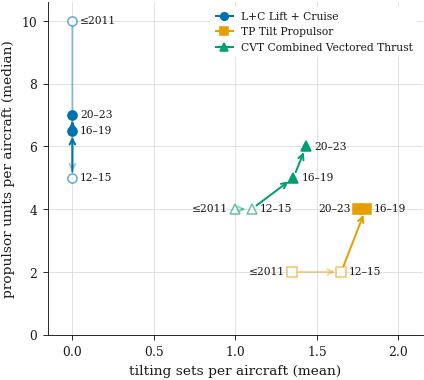

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_class_centres_tilting_units.pdf')

In [64]:
item(m6, 'q6_class_centres_tilting_units')

#### D. Tilt Propulsor units by tilting sets

Median propulsor units of the Tilt Propulsor aircraft with one, two, and three or more tilting sets, all years. *(from Figure 14 (ii))*

appendix | Figure 14 (ii) |  -> q6_tp_units_by_tilting_sets.pdf


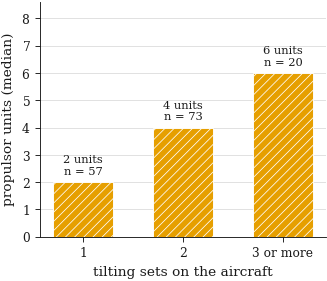

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_tp_units_by_tilting_sets.pdf')

In [65]:
item(m6, 'q6_tp_units_by_tilting_sets')

#### D. CVT aircraft with units on booms

Share of CVT aircraft that carry propulsor units on booms per complete window. *(from Figure 14 (iii))*

appendix | Figure 14 (iii) |  -> q6_cvt_units_on_booms.pdf


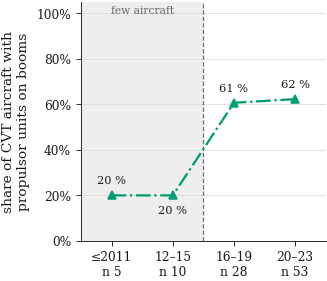

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_cvt_units_on_booms.pdf')

In [66]:
item(m6, 'q6_cvt_units_on_booms')

#### D. CVT ducting inside each boom layout

Share of CVT aircraft with a ducted propulsor unit, one line for the aircraft with propulsor units on booms and one for those without, each with its trend test. *(from Figure 14 (iv))*

appendix | Figure 14 (iv) |  -> q6_cvt_ducted_by_boom_layout.pdf


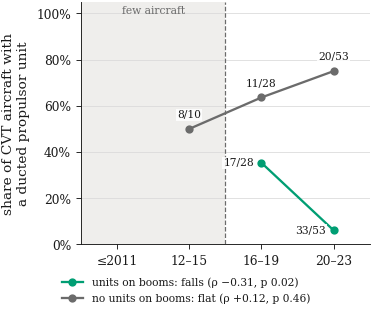

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_cvt_ducted_by_boom_layout.pdf')

In [67]:
item(m6, 'q6_cvt_ducted_by_boom_layout')

#### D. Propulsor units on booms per class

Share of each class's aircraft that carry propulsor units on booms per complete window. *(from Figure 15 (i))*

appendix | Figure 15 (i) |  -> q6_boom_share_by_class.pdf


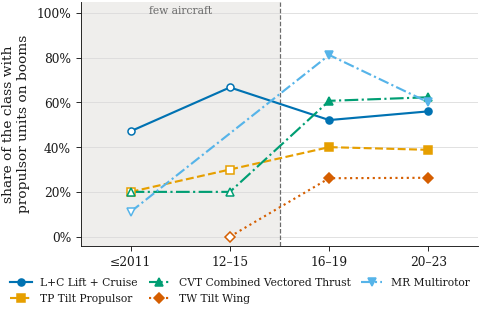

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_boom_share_by_class.pdf')

In [68]:
item(m6, 'q6_boom_share_by_class')

#### D. Ducted propulsor unit per class

Share of each class's aircraft with at least one ducted propulsor unit per complete window. *(from Figure 15 (ii))*

appendix | Figure 15 (ii) |  -> q6_ducted_share_by_class.pdf


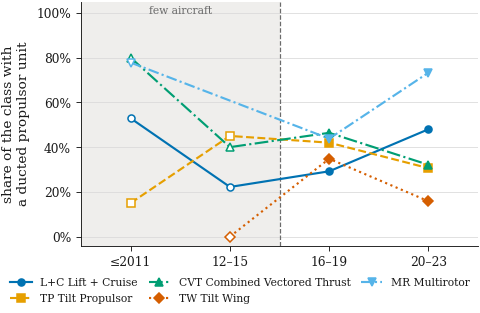

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_ducted_share_by_class.pdf')

In [69]:
item(m6, 'q6_ducted_share_by_class')

#### D. Traces that move and their drivers

The traces that move inside at least one class or in the five classes pooled: where each moved, with ρ and p, and the drivers it goes with and against. *(from Table 9)*

In [70]:
item(m6, 'q6_driver_verdicts')

appendix | Table 9 |  -> q6_driver_verdicts.csv


,trace,where it moved (every year to 2023),goes with (driver: what it predicts),goes against (driver: what it predicts),what it means
0,● tilting sets per aircraft,"rises in Tilt Propulsor (ρ +0.22, p 0.01); ris...",regime transition (more),development and certification cost (fewer); ma...,drivers disagree; it moved with those under 'g...
1,a body that tilts or rotates,"falls in Multirotor (ρ -0.37, p 0.01); pooled:...",occupant presence (fewer),regime transition (more),drivers disagree; it moved with those under 'g...
2,● propulsor units per aircraft,"rises in Tilt Propulsor (ρ +0.41, p < 0.001); ...",distributed propulsion and propulsor control (...,—,3 drivers predict it; the labelled dataset can...
3,● propulsor units carried on booms,"rises in CVT (ρ +0.22, p 0.03); rises in Tilt ...",distributed propulsion and propulsor control (...,—,"one driver predicts it, and it moved that way"
4,places carrying propulsor units per aircraft,"rises in Tilt Propulsor (ρ +0.19, p 0.03); poo...",distributed propulsion and propulsor control (...,—,"one driver predicts it, and it moved that way"
5,booms present,no trend detected in any class; pooled: rises,—,—,no driver predicts a direction; only physical ...
6,a pusher unit,no trend detected in any class; pooled: rises,—,—,no driver predicts a direction; only physical ...
7,two or more wing panels,no trend detected in any class; pooled: rises,mission range and speed (either way),—,"one driver predicts it, and it moved that way"
8,no tail surface,"falls in CVT (ρ -0.30, p 0.003); pooled: flat",—,—,no driver predicts a direction; only physical ...
9,landing gear drawn,"rises in Multirotor (ρ +0.38, p 0.01); pooled:...",payload (either way); operating environment (e...,—,3 drivers predict it; the labelled dataset can...


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/appendix/q6_driver_verdicts.csv')

### Q6 — numbers and text checks

Every number the Q6 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [71]:
nums = thesis_run.write_numbers('Q6', ctx)
problems = thesis_run.check_text('Q6', nums, [i['name'] for i in m6.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 177 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q6_design_space/numbers.json
text checks: clean


,value
n_aircraft,627
last_year,2023
partial_start,2024
trend_min,20
alpha,0.05
...,...
spu_w4,0.39
spu_rho,−0.32
spu_p,< 0.001
spu_cvt_p,0.41


## Q7. Is there a dominant design?

*Convergence analysis.* Module `viz/thesis_q7.py`; text `viz/thesis_text_q7.py`.

In [72]:
from viz import thesis_q7 as m7
importlib.reload(m7)
print(len(m7.ITEMS), 'items')

10 items


### Q7 — Method

#### How Q7 is answered

How Q7 is answered. *(from new)*

method | new |  -> q7_method_flow.pdf


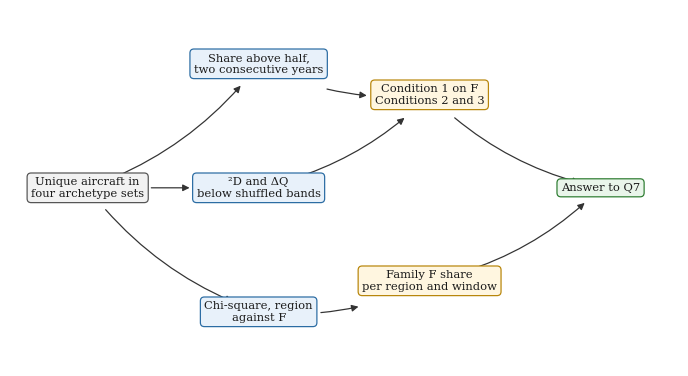

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/method/q7_method_flow.pdf')

In [73]:
item(m7, 'q7_method_flow')

### Q7 — Results

#### A. The four archetype sets

The four archetype sets the test is run in: archetypes, singletons, the effective number ¹D and the largest archetype with its share, whole corpus, all years. F was defined after the first readings of the data. *(from Table 7)*

In [74]:
item(m7, 'q7_archetype_sets')

results | Table 7 |  -> q7_archetype_sets.csv


,archetype set,archetypes,singletons,¹D,largest archetype,its share
0,C (class),12,0,7.3,Lift + Cruise,26 %
1,C·W·T (class + wings + tilt),39,10,16.4,Lift + Cruise · one wing · no tilting propulsor,17 %
2,C·U (class + propulsor units),43,3,29.4,Tilt Propulsor · 1-3 propulsor units,10 %
3,F (Lift + Cruise + CVT* family),12,0,6.2,Lift + Cruise + CVT* family,39 %


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/results/q7_archetype_sets.csv')

#### B. Condition 1 on F per priority year

Condition 1 on F per priority year, as its share of the aircraft with a patent in force and of all aircraft against the 50 % line. The ringed years meet it. *(from Figure 11)*

results | Figure 11 |  -> q7_condition1_family.pdf


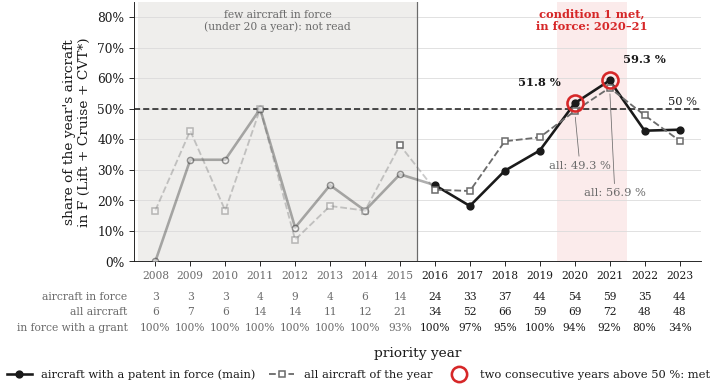

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/results/q7_condition1_family.pdf')

In [75]:
item(m7, 'q7_condition1_family')

#### B. Condition 2: ²D against its band

Condition 2 per window in the four archetype sets, ²D rarefied to 40 aircraft against the band of the same archetypes shuffled among the windows. A red point is below the band. *(from Figure 12 (i))*

results | Figure 12 (i) |  -> q7_condition2_balance.pdf


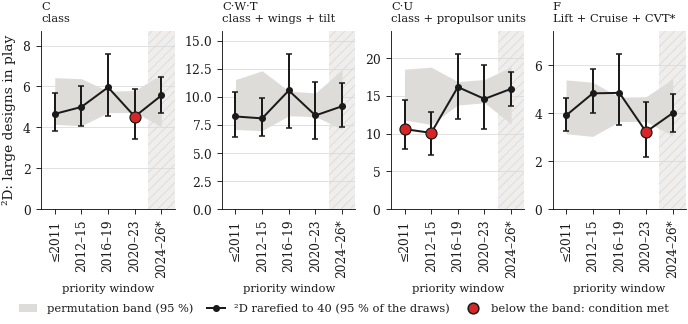

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/results/q7_condition2_balance.pdf')

In [76]:
item(m7, 'q7_condition2_balance')

#### B. Condition 3: ΔQ against its band

Condition 3 per window. ΔQ is the change in the average Gower distance between two aircraft against the two earliest windows, drawn under the main weighting (solid, grey band) and the check (dashed, dotted edges). *(from Figure 12 (ii))*

results | Figure 12 (ii) |  -> q7_condition3_cohesion.pdf


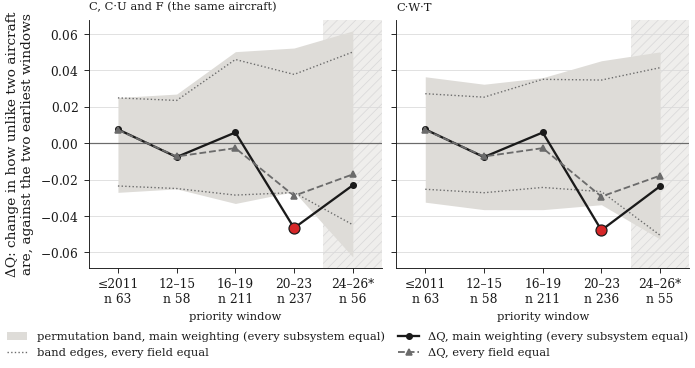

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/results/q7_condition3_cohesion.pdf')

In [77]:
item(m7, 'q7_condition3_cohesion')

#### D. Family F share per region and window

Each region's share of aircraft in F per priority window from 2012, with the chi-square p of the regional difference under each window. *(from Figure 24 (i))*

results | Figure 24 (i) |  -> q7_region_family_share.pdf


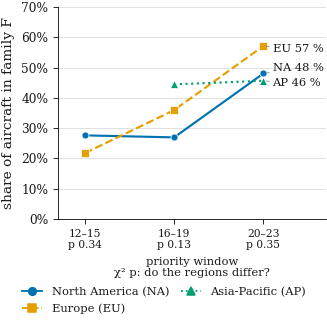

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/results/q7_region_family_share.pdf')

In [78]:
item(m7, 'q7_region_family_share')

### Q7 — Appendix

#### B. The dominant-design verdict

The verdict per condition and archetype set, naming the priority years (condition 1) or windows (conditions 2 and 3) where each condition is met (✓) or not (✗); condition 1 on both bases, condition 3 under the main weighting. *(from Table 8)*

In [79]:
item(m7, 'q7_verdict_table')

appendix | Table 8 |  -> q7_verdict_table.csv


,condition,C,C·W·T,C·U,F (defined after the first readings)
0,"1, counts: one archetype above 50 % of the air...","in force: ✗ not met, at most 39.0 % (2021); al...","in force: ✗ not met, at most 27.1 % (2021); al...","in force: ✗ not met, at most 23.7 % (2021); al...","in force: ✓ met in 2020 and 2021 (51.8 %, 59.3..."
1,"2, balance: ²D below the permutation band",✓ met in 2020-23,✗ not met,"✓ met in <= 2011, 2012-15",✓ met in 2020-23
2,"3, form: Q below the two earliest windows by m...",✓ met in 2020-23,✓ met in 2020-23,✓ met in 2020-23,✓ met in 2020-23
3,all three in the same period,✗ not met,✗ not met,✗ not met,✓ met in 2020-23


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/appendix/q7_verdict_table.csv')

#### D. Tilting lean with and without the largest filer

The share of each region's aircraft with a tilting propulsor and its Tilt Propulsor share, all years. The hatched bar is North America without its largest filer, Bell / Textron. *(from Figure 24 (ii))*

appendix | Figure 24 (ii) |  -> q7_region_lean_without_largest_filer.pdf


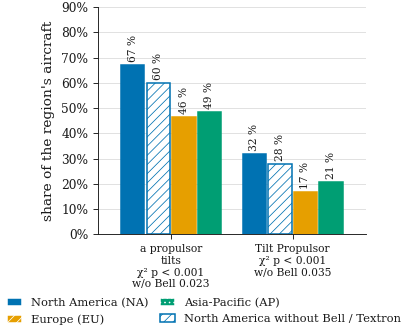

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/appendix/q7_region_lean_without_largest_filer.pdf')

In [80]:
item(m7, 'q7_region_lean_without_largest_filer')

#### D. Proximity of firms within and across regions

The proximity of the class-share profiles of the 16 firms with 5 aircraft or more, by region pair, with the mean of the firm pairs (marker) and the lowest to the highest pair (bar). *(from Figure 24 (iii))*

appendix | Figure 24 (iii) |  -> q7_region_firm_proximity.pdf


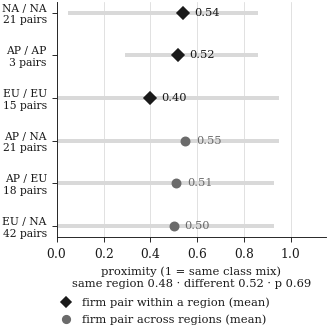

PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/appendix/q7_region_firm_proximity.pdf')

In [81]:
item(m7, 'q7_region_firm_proximity')

#### What the labelled dataset cannot answer

The eight stakeholder questions the labelled dataset answers only in part or not at all, with the reason. Printed in the Limitations chapter. *(from Table 10)* — **drop**: limitations table

In [82]:
item(m7, 'q7_cannot_answer')

appendix | Table 10 | FLAG drop: limitations table -> q7_cannot_answer.csv


,Question,Verdict,Why
0,Do patents track substance rather than press a...,no,The only handle is the citation rank of the in...
1,Do filings lead or lag commercial emergence?,partly,Holds for the five largest classes only; the c...
2,"Are there hype cycles, exotic configurations l...",partly,"Legal status is a snapshot, alive or dead at t..."
3,Is convergence happening inside one mission se...,no,Mission is not a label. It exists only for the...
4,Where is the mechanical white space against al...,no,"The labels describe what is drawn, never what ..."
5,Is hybrid-electric a bridge or a dead end?,no,An aircraft that needs a combustion engine to ...
6,Which architectures are the safer certificatio...,no,No certification data of any kind is in the co...
7,Are architectures specialising into mission ni...,no,"The mission gap again, and no size handle to s..."


PosixPath('/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/appendix/q7_cannot_answer.csv')

### Q7 — numbers and text checks

Every number the Q7 text quotes, written to `numbers.json`; then the text module is checked (unresolved placeholders, missing references, density).

In [83]:
nums = thesis_run.write_numbers('Q7', ctx)
problems = thesis_run.check_text('Q7', nums, [i['name'] for i in m7.ITEMS])
print('\n'.join(problems) if problems else 'text checks: clean')
pd.Series(nums, name='value').to_frame()

  numbers.json: 110 values -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/Q7_dominant_design/numbers.json
text checks: clean


,value
w_last,2020-23
w_early,2012-15
w_mid,2016-19
w_first,2012
met_years,2020 and 2021
...,...
px_eu,0.40
px_na,0.54
px_ap,0.52
pub_n,97


## Figure map

One row per item: question, sub-question, slot, where it comes from, the author's flag, and the folder.

In [84]:
mods = [importlib.import_module(f'viz.thesis_q{q[1]}') for q, *_ in thesis.QUESTIONS]
fm = thesis.figure_map(cfg, mods)
print(len(fm), 'items ->', OUT / 'FIGURE_MAP.csv')
fm[['question', 'sub', 'slot', 'kind', 'name', 'from document', 'flag']]

67 items -> /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures/FIGURE_MAP.csv


,question,sub,slot,kind,name,from document,flag
0,Q1,,method,figure,q1_method_flow,new,
1,Q1,A,results,figure,q1_filings_per_year,Figure 1 (i),
2,Q1,A,results,figure,q1_growth_rates,Figure 1 (ii),
3,Q1,A,appendix,table,q1_growth_rates_table,la_growth_rates / la_growth_ratios (Figure 1 i...,
4,Q1,B,appendix,figure,q1_na_drop_is_real,Figure 23 (i),
...,...,...,...,...,...,...,...
62,Q7,B,appendix,table,q7_verdict_table,Table 8,
63,Q7,D,results,figure,q7_region_family_share,Figure 24 (i),
64,Q7,D,appendix,figure,q7_region_lean_without_largest_filer,Figure 24 (ii),
65,Q7,D,appendix,figure,q7_region_firm_proximity,Figure 24 (iii),
